# Slope Chart

**Family:** Ranking &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Ranking:* Use when an item's position in an ordered list matters more than its absolute value.

## Design purpose

Joins each item's value at two points in time (or two conditions) with a straight line. The slope shows the direction and size of change, and crossing lines show changes in rank.

## When to use

- Compare rankings or values between exactly two time points or conditions
- Highlight which items rose and which fell

## Avoid when

- There are more than two time points (use a bump or line chart)
- There are too many items, so lines and labels collide (~15 max)

## Alternatives

- Dumbbell chart
- Bump chart
- Grouped bar chart

## Design tips

- Color by direction (up/down) or highlight a few items and gray the rest
- Label both ends directly; no legend needed

## Example

Market share (%) of 8 smartphone brands in 2019 vs. 2024 (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })

### Data

In [2]:
brands = ["Atlas", "Borealis", "Cirrus", "Delta", "Echo", "Flux", "Gamma", "Helix"]
y2019 = [21.0, 18.5, 14.0, 11.0, 9.5, 8.0, 6.0, 4.5]
y2024 = [19.5, 12.0, 17.5, 6.5, 13.5, 8.5, 9.5, 3.5]
df = pd.DataFrame({"brand": brands, "2019": y2019, "2024": y2024})
start, end = "2019", "2024"
title = "Smartphone market share (%), 2019 → 2024"
df["change"] = df[end] - df[start]
df

,brand,2019,2024,change
0,Atlas,21.0,19.5,-1.5
1,Borealis,18.5,12.0,-6.5
2,Cirrus,14.0,17.5,3.5
3,Delta,11.0,6.5,-4.5
4,Echo,9.5,13.5,4.0
5,Flux,8.0,8.5,0.5
6,Gamma,6.0,9.5,3.5
7,Helix,4.5,3.5,-1.0


### Plot

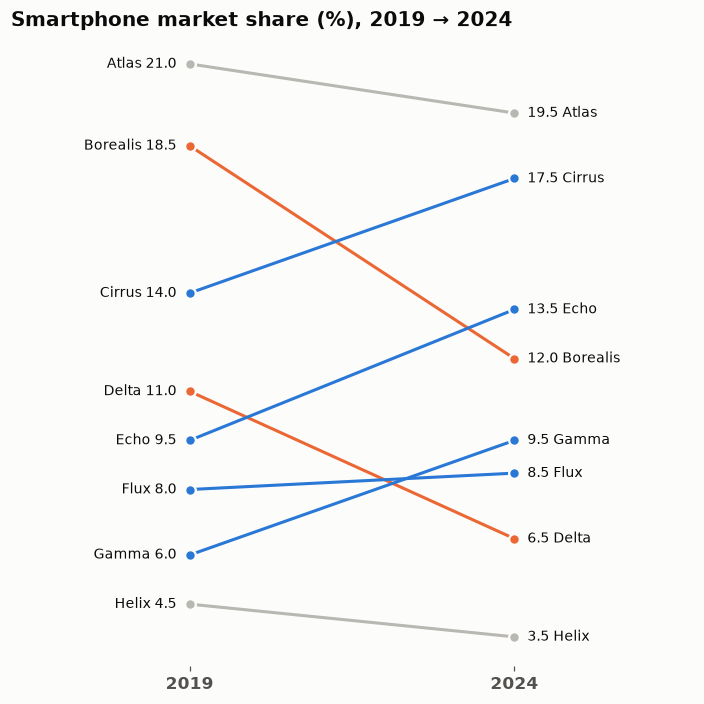

In [3]:
from matplotlib import patheffects
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for _, r in df.iterrows():
    color = PALETTE[0] if r["change"] > 0 else PALETTE[1] if r["change"] < -2 else GRAY
    ax.plot([0, 1], [r[start], r[end]], color=color, marker="o", markersize=7,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ax.text(-0.04, r[start], f"{r['brand']} {r[start]:.1f}", ha="right", va="center", fontsize=9)
    ax.text(1.04, r[end], f"{r[end]:.1f} {r['brand']}", ha="left", va="center", fontsize=9)
ax.set_xlim(-0.55, 1.55)
ax.set_xticks([0, 1], [start, end], fontsize=11, weight="bold")
ax.yaxis.set_visible(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.grid(False)
ax.set_title(title)
fig.tight_layout()
plt.show()

## How to read it

Blue lines gained share and orange lines lost more than two points. Echo and Cirrus rose, while Borealis and Delta fell sharply.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### altair

In [4]:
import altair as alt
long = df.melt(id_vars=["brand", "change"], value_vars=[start, end], var_name="year", value_name="value")
long["direction"] = np.where(long["change"] > 0, "Up", np.where(long["change"] < -2, "Down", "Flat"))
base = alt.Chart(long).encode(
    x=alt.X("year:N", title=None, axis=alt.Axis(labelAngle=0)),
    y=alt.Y("value:Q", title=None, scale=alt.Scale(zero=False)),
    color=alt.Color("direction:N", scale=alt.Scale(domain=["Up", "Down", "Flat"],
                                                   range=[PALETTE[0], PALETTE[1], "#b8b7b1"]), title=None),
    detail="brand:N")
chart = (base.mark_line(point=True) + base.mark_text(dx=8, align="left").encode(text="brand:N")
         .transform_filter(alt.datum.year == end)).properties(title=title, width=300, height=420)
chart

alt.LayerChart(...)

## Try it with real data

**Source:** plotly.express.data.gapminder() — Gapminder life expectancy, GDP and population 1952–2007, bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [5]:
import plotly.express as px
countries = ["Japan", "China", "Iraq", "India", "Zimbabwe", "Nigeria"]
gm = px.data.gapminder().query("year in [1987, 2007] and country in @countries")
df = (gm.pivot(index="country", columns="year", values="lifeExp")
        .rename(columns=str).rename_axis(columns=None).reset_index().rename(columns={"country": "brand"}))
start, end = "1987", "2007"
title = "Life expectancy (years), 1987 → 2007"
df["change"] = df[end] - df[start]
df

,brand,1987,2007,change
0,China,67.274,72.961,5.687
1,India,58.553,64.698,6.145
2,Iraq,65.044,59.545,-5.499
3,Japan,78.670,82.603,3.933
4,Nigeria,46.886,46.859,-0.027
5,Zimbabwe,62.351,43.487,-18.864


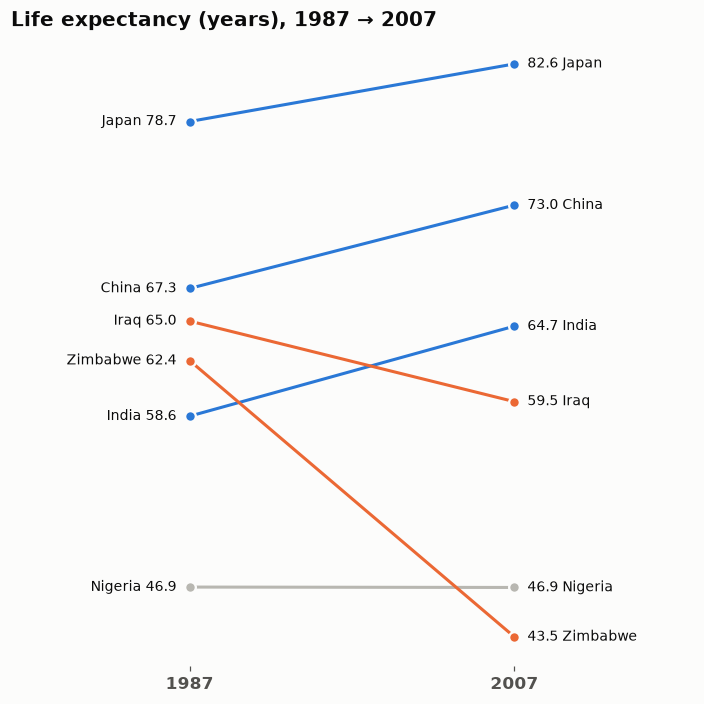

In [6]:
from matplotlib import patheffects
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for _, r in df.iterrows():
    color = PALETTE[0] if r["change"] > 0 else PALETTE[1] if r["change"] < -2 else GRAY
    ax.plot([0, 1], [r[start], r[end]], color=color, marker="o", markersize=7,
            markeredgecolor="#fcfcfb", markeredgewidth=1.5)
    ax.text(-0.04, r[start], f"{r['brand']} {r[start]:.1f}", ha="right", va="center", fontsize=9)
    ax.text(1.04, r[end], f"{r[end]:.1f} {r['brand']}", ha="left", va="center", fontsize=9)
ax.set_xlim(-0.55, 1.55)
ax.set_xticks([0, 1], [start, end], fontsize=11, weight="bold")
ax.yaxis.set_visible(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_visible(False)
ax.grid(False)
ax.set_title(title)
fig.tight_layout()
plt.show()

---
Standalone script: [`slope_chart.py`](slope_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)